<a href="https://colab.research.google.com/github/rounakjha52-cmd/ai-in-cybersecurity-assignment-2/blob/main/Lab_2_Suspicious_Login_ML_Rounak_Jha.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

CSV_FILE = "simple_login_activity.csv"

if not os.path.exists(CSV_FILE):
    try:
        from google.colab import files
        uploaded = files.upload()
        uploaded_csvs = [name for name in uploaded if name.lower().endswith(".csv")]
        if uploaded_csvs:
            CSV_FILE = uploaded_csvs[0]
    except ImportError:
        print("Place simple_login_activity.csv in the notebook's working directory.")

df = pd.read_csv(CSV_FILE)

required_columns = {
    "record_id", "failed_logins", "login_hour",
    "new_device", "download_mb", "label"
}
missing_columns = required_columns - set(df.columns)
if missing_columns:
    raise ValueError(f"CSV is missing required columns: {sorted(missing_columns)}")

display(df.head())
print("Dataset shape:", df.shape)

Saving simple_login_activity (1).csv to simple_login_activity (1) (1).csv


,record_id,failed_logins,login_hour,new_device,download_mb,label
0,1,4.0,1,0,164.9,Suspicious
1,2,3.0,3,1,250.6,Suspicious
2,3,3.0,10,0,145.1,Normal
3,4,2.0,11,0,397.8,Normal
4,5,1.0,3,0,409.3,Normal


Dataset shape: (101, 6)


## Q1. Dataset Inspection and Cleaning (5 marks)

### Aim
Identify the input columns and target label, remove duplicate rows, and fill missing numeric values.

### Theory
- Models need complete and consistent data.
- The median is a robust choice for filling missing numeric values.
- Duplicate rows can distort analysis.
- **Target label:** `Normal` / `Suspicious`.
- **Input features:** `failed_logins`, `login_hour`, `new_device`, `download_mb`.

In [2]:
print("Dataset information:")
df.info()

print("\nMissing values before cleaning:")
print(df.isna().sum())

print("\nDuplicate rows before cleaning:", df.duplicated().sum())

# Remove exact duplicate rows.
df = df.drop_duplicates().copy()

# Fill missing numeric values with their respective medians.
numeric_columns = ["failed_logins", "login_hour", "new_device", "download_mb"]
for column in numeric_columns:
    df[column] = df[column].fillna(df[column].median())

# Validate target labels.
print("\nTarget label counts:")
print(df["label"].value_counts())

print("\nMissing values after cleaning:", df.isna().sum().sum())
print("Duplicate rows after cleaning:", df.duplicated().sum())
print("Final rows:", len(df))

display(df.head())

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 101 entries, 0 to 100
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   record_id      101 non-null    int64  
 1   failed_logins  100 non-null    float64
 2   login_hour     101 non-null    int64  
 3   new_device     101 non-null    int64  
 4   download_mb    100 non-null    float64
 5   label          101 non-null    object 
dtypes: float64(2), int64(3), object(1)
memory usage: 4.9+ KB

Missing values before cleaning:
record_id        0
failed_logins    1
login_hour       0
new_device       0
download_mb      1
label            0
dtype: int64

Duplicate rows before cleaning: 1

Target label counts:
label
Normal        75
Suspicious    25
Name: count, dtype: int64

Missing values after cleaning: 0
Duplicate rows after cleaning: 0
Final rows: 100


,record_id,failed_logins,login_hour,new_device,download_mb,label
0,1,4.0,1,0,164.9,Suspicious
1,2,3.0,3,1,250.6,Suspicious
2,3,3.0,10,0,145.1,Normal
3,4,2.0,11,0,397.8,Normal
4,5,1.0,3,0,409.3,Normal


### Q1 – Observation
The supplied dataset contains 101 rows before cleaning. It has one missing value in `failed_logins`, one missing value in `download_mb`, and one duplicate row. After removing the duplicate and filling the missing numeric values with their medians, the dataset contains 100 rows with no missing values or duplicate rows.

## Q2. Training and Testing Split (5 marks)

### Aim
Separate the input features and target label, then create a 75/25 train-test split.

### Theory
- Training data is used by the model to learn patterns.
- Testing data measures performance on unseen records.
- A stratified split preserves class proportions in both sets.
- `random_state=42` makes the split reproducible.

In [3]:
features = ["failed_logins", "login_hour", "new_device", "download_mb"]
X = df[features]
y = df["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

print("\nTraining label proportions:")
print(y_train.value_counts(normalize=True).round(3))

print("\nTesting label proportions:")
print(y_test.value_counts(normalize=True).round(3))

Training rows: 75
Testing rows: 25

Training label proportions:
label
Normal        0.747
Suspicious    0.253
Name: proportion, dtype: float64

Testing label proportions:
label
Normal        0.76
Suspicious    0.24
Name: proportion, dtype: float64


### Q2 – Observation
The cleaned dataset is split into 75 training rows and 25 testing rows. Testing on unseen records is important because evaluating on the same data used for training can give an overly optimistic estimate of performance.

## Q3. Decision Tree Training and Evaluation (10 marks)

### Aim
Train a Decision Tree and evaluate its accuracy and confusion matrix.

### Theory
- A Decision Tree learns if-then decision rules from labelled data.
- `max_depth=4` keeps the tree relatively readable and can reduce overfitting.
- A confusion matrix shows correct Normal/Suspicious decisions, false positives and false negatives.

Accuracy: 88.00%

Confusion matrix (rows = actual, columns = predicted):
[[19  0]
 [ 3  3]]


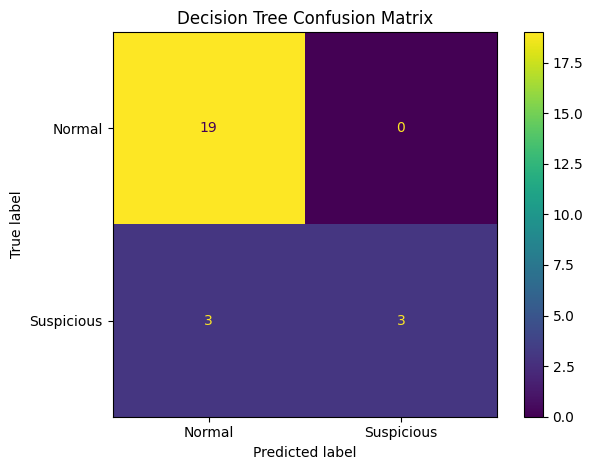

True negatives (Normal correctly predicted): 19
False positives (Normal predicted Suspicious): 0
False negatives (Suspicious predicted Normal): 3
True positives (Suspicious correctly predicted): 3


In [4]:
model = DecisionTreeClassifier(max_depth=4, random_state=42)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy * 100:.2f}%")

labels_order = ["Normal", "Suspicious"]
cm = confusion_matrix(y_test, y_pred, labels=labels_order)
print("\nConfusion matrix (rows = actual, columns = predicted):")
print(cm)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=labels_order
).plot()
plt.title("Decision Tree Confusion Matrix")
plt.tight_layout()
plt.show()

tn, fp, fn, tp = cm.ravel()
print("True negatives (Normal correctly predicted):", tn)
print("False positives (Normal predicted Suspicious):", fp)
print("False negatives (Suspicious predicted Normal):", fn)
print("True positives (Suspicious correctly predicted):", tp)

### Q3 – Observation
The supplied lab material reports **88.00% accuracy** and confusion matrix `[[19, 0], [3, 3]]` for its example run. The output above is calculated from the uploaded CSV and the reproducible split in this notebook. Genuine and suspicious login behaviour can overlap, so a score below 100% can be realistic. False negatives are especially important because they represent suspicious records the model missed.

## Q4. K-Means Clustering (10 marks)

### Aim
Group similar login activity without using the target labels, then compare the clusters with the known labels.

### Theory
- K-Means is an unsupervised learning algorithm: it does not use the `label` column to create clusters.
- Features have different scales (for example, login hour and downloaded MB), so standardization is important.
- Clusters do not have to match the Normal/Suspicious labels perfectly.

In [5]:
# Standardize the numeric input features before clustering.
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)
df["cluster"] = kmeans.fit_predict(X_scaled)

cluster_summary = df.groupby("cluster")[features].mean().round(2)
label_summary = pd.crosstab(df["cluster"], df["label"])

print("Average feature values by cluster:")
display(cluster_summary)

print("Cluster compared with actual labels:")
display(label_summary)

# Calculate the suspicious proportion in each cluster.
cluster_comparison = label_summary.copy()
cluster_comparison["Total"] = cluster_comparison.sum(axis=1)
if "Suspicious" in cluster_comparison.columns:
    cluster_comparison["Suspicious rate (%)"] = (
        cluster_comparison["Suspicious"] / cluster_comparison["Total"] * 100
    ).round(1)

display(cluster_comparison)

Average feature values by cluster:


,failed_logins,login_hour,new_device,download_mb
cluster,,,,
0,2.00,12.81,1.0,192.69
1,2.16,11.63,0.0,236.15


Cluster compared with actual labels:


label,Normal,Suspicious
cluster,,
0,24,13
1,51,12


label,Normal,Suspicious,Total,Suspicious rate (%)
cluster,,,,
0,24,13,37,35.1
1,51,12,63,19.0


### Q4 – Observation
K-Means groups records by similarity in the standardized numeric features, not by their supplied labels. Compare the number and percentage of Suspicious records in each cluster. A cluster with a higher suspicious proportion may deserve closer review, but the cluster itself is not a security verdict.

## Q5. Feature Importance and New Record Prediction (5 marks)

### Aim
Identify which features the Decision Tree used most and predict the labels of three new example login records.

### Theory
Feature importance indicates how much each feature contributed to the trained tree's splits. It is model-specific and does not prove that a feature causes suspicious activity.

,feature,importance
1,login_hour,0.413391
0,failed_logins,0.392826
3,download_mb,0.193783
2,new_device,0.000000


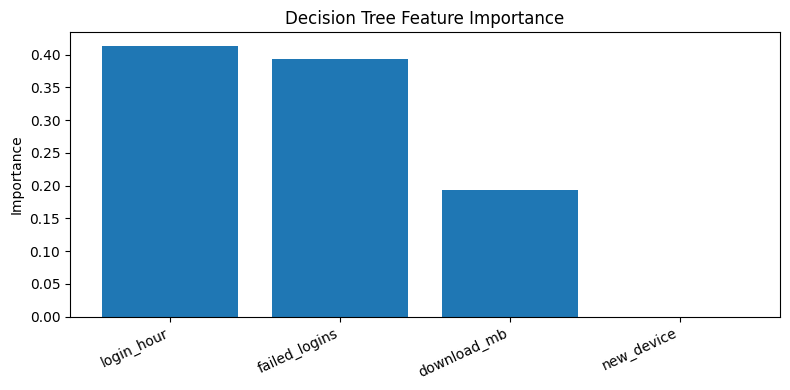

In [6]:
importance = pd.DataFrame({
    "feature": features,
    "importance": model.feature_importances_
}).sort_values("importance", ascending=False)

display(importance)

plt.figure(figsize=(8, 4))
plt.bar(importance["feature"], importance["importance"])
plt.title("Decision Tree Feature Importance")
plt.ylabel("Importance")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

In [7]:
# Three example records, using the same feature columns as the training data.
new_records = pd.DataFrame([
    {"failed_logins": 0, "login_hour": 10, "new_device": 0, "download_mb": 45},
    {"failed_logins": 8, "login_hour": 2, "new_device": 1, "download_mb": 180},
    {"failed_logins": 2, "login_hour": 23, "new_device": 1, "download_mb": 900}
])

new_records["prediction"] = model.predict(new_records[features])
display(new_records)

,failed_logins,login_hour,new_device,download_mb,prediction
0,0,10,0,45,Normal
1,8,2,1,180,Suspicious
2,2,23,1,900,Suspicious


### Q5 – Observation
The example output in the supplied lab material lists `login_hour`, `failed_logins` and `download_mb` as the most important features, with `new_device` having zero importance in that example. The actual importance values and predictions are generated from the model trained in this notebook.

## Q6. False Positives, False Negatives and Reflection (5 marks)

### Aim
Understand two important model errors and summarize the model's suitability.

- **False positive:** genuine activity is incorrectly marked Suspicious, which can waste an analyst's time.
- **False negative:** a real suspicious event is marked Normal, so an attack may be missed.

A legitimate late-night login on a new device can be flagged as Suspicious. A disguised attack with few obvious indicators may be classified as Normal.

In [8]:
# Show actual false positives and false negatives in the held-out test set.
test_check = X_test.copy()
test_check["actual"] = y_test
test_check["predicted"] = y_pred

false_positives = test_check[
    (test_check["actual"] == "Normal") &
    (test_check["predicted"] == "Suspicious")
]

false_negatives = test_check[
    (test_check["actual"] == "Suspicious") &
    (test_check["predicted"] == "Normal")
]

print("False positive records:")
display(false_positives)

print("False negative records:")
display(false_negatives)

print("False positive count:", len(false_positives))
print("False negative count:", len(false_negatives))

False positive records:


,failed_logins,login_hour,new_device,download_mb,actual,predicted


False negative records:


,failed_logins,login_hour,new_device,download_mb,actual,predicted
45,3.0,4,1,142.8,Suspicious,Normal
54,4.0,15,1,316.9,Suspicious,Normal
71,3.0,18,1,151.3,Suspicious,Normal


False positive count: 0
False negative count: 3


### Reflection and conclusion

The Decision Tree provides a simple way to classify login activity using failed login attempts, login time, new-device status and downloaded data volume. The train-test split gives an estimate of how well the model performs on unseen records, while the confusion matrix helps identify false alarms and missed suspicious activity. K-Means provides a separate, unsupervised view of patterns in the login data.

The model has limitations: the dataset contains only 100 cleaned records and four numeric input features. It does not include other potentially useful signals such as IP reputation or geographic location. A legitimate user may log in at an unusual hour or use a new device, while an attacker may produce activity that looks normal. Therefore, model predictions should support—not replace—human analysis. Suspicious predictions and unusual cases classified as Normal should be reviewed by a human analyst before action is taken.

## Save the final result

Save the cleaned dataset with its K-Means cluster assignment as `Lab2_Login_ML_Result.csv`. The Decision Tree test predictions and error examples are displayed in the cells above.

In [9]:
output_file = "Lab2_Login_ML_Result.csv"
df.to_csv(output_file, index=False)
print("Saved:", output_file)

try:
    from google.colab import files
    files.download(output_file)
except ImportError:
    print("The result CSV is saved in the current working directory.")

Saved: Lab2_Login_ML_Result.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Lab file notes

- **Q1:** Inputs — `failed_logins`, `login_hour`, `new_device`, `download_mb`; target — `label`. The supplied CSV has one missing `failed_logins`, one missing `download_mb`, and one duplicate row. After cleaning: 100 rows, no missing values and no duplicates.
- **Q2:** 75 training rows and 25 testing rows, using a stratified split and `random_state=42`.
- **Q3:** Record the accuracy and confusion matrix printed by your run. Interpret false positives and false negatives.
- **Q4:** Compare the cluster feature averages and label counts. K-Means does not use the labels to form clusters.
- **Q5:** Record the feature importance ranking and the three new-record predictions from your run.
- **Q6:** Discuss false positives, false negatives, dataset limitations and the need for human review.

## Submission checklist
- [x] Dataset inspection and cleaning
- [x] 75/25 stratified train-test split
- [x] Decision Tree training, accuracy and confusion matrix
- [x] K-Means clustering and label comparison
- [x] Feature importance and three new predictions
- [x] False-positive and false-negative review
- [x] Conclusion and CSV export

**Before submission:** Run every cell from top to bottom, check your outputs, and submit the executed notebook with `Lab2_Login_ML_Result.csv`.